In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, recall_score, precision_score, f1_score, roc_curve, confusion_matrix

In [6]:
df = pd.read_csv('breast_cancer_prediction.csv')

In [7]:
df

,Patient_ID,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,...,Mammogram_Result,Biopsy_Result,Cancer_Stage,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Breastfeeding_History,Annual_Income_USD
0,100001,71,Female,27.2,Yes,Yes,Yes,High,No,Post,...,Suspicious,Malignant,Stage II,1,141,167,No,7,No,101316
1,100002,34,Male,26.0,No,No,No,High,No,Post,...,Normal,Benign,No Cancer,0,104,229,Yes,7,Yes,30023
2,100003,80,Female,20.7,No,No,No,High,No,Pre,...,Suspicious,Benign,No Cancer,0,161,275,No,1,Yes,34819
3,100004,40,Female,26.8,Yes,Yes,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,150,180,No,7,Yes,68025
4,100005,43,Female,28.6,Yes,Yes,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,110,266,No,0,Yes,90919
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,109996,84,Female,31.4,No,No,Yes,High,No,Post,...,Normal,Benign,No Cancer,0,117,166,No,5,Not Applicable,46779
9996,109997,43,Female,24.7,No,Yes,No,Moderate,Yes,Pre,...,Abnormal,Benign,No Cancer,0,116,169,No,7,No,110807
9997,109998,23,Female,26.2,Yes,No,Yes,Moderate,No,Pre,...,Normal,Benign,No Cancer,0,140,214,No,6,No,126164
9998,109999,44,Female,21.8,No,No,No,Moderate,No,Post,...,Abnormal,Benign,No Cancer,0,153,175,No,4,Not Applicable,89761


In [8]:
df.info()
df.describe(include='all')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Patient_ID              10000 non-null  int64  
 1   Age                     10000 non-null  int64  
 2   Gender                  10000 non-null  object 
 3   BMI                     9700 non-null   float64
 4   Family_History          10000 non-null  object 
 5   Smoking                 10000 non-null  object 
 6   Alcohol_Consumption     9700 non-null   object 
 7   Physical_Activity       9700 non-null   object 
 8   Hormone_Therapy         9700 non-null   object 
 9   Menopause_Status        10000 non-null  object 
 10  Genetic_Mutation        10000 non-null  object 
 11  Tumor_Size_cm           9700 non-null   float64
 12  Lymph_Node_Involvement  10000 non-null  object 
 13  Mammogram_Result        10000 non-null  object 
 14  Biopsy_Result           10000 non-null 

,Patient_ID,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,...,Mammogram_Result,Biopsy_Result,Cancer_Stage,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Breastfeeding_History,Annual_Income_USD
count,10000.00000,10000.000000,10000,9700.000000,10000,10000,9700,9700,9700,10000,...,10000,10000,10000,10000.000000,10000.000000,10000.000000,10000,10000.000000,10000,10000.000000
unique,NaN,NaN,2,NaN,2,2,2,3,2,2,...,3,2,5,NaN,NaN,NaN,2,NaN,3,NaN
top,NaN,NaN,Female,NaN,No,No,No,Moderate,No,Post,...,Normal,Benign,No Cancer,NaN,NaN,NaN,No,NaN,Yes,NaN
freq,NaN,NaN,9277,NaN,6979,7462,6319,4379,7704,5509,...,6481,8067,8067,NaN,NaN,NaN,8296,NaN,4514,NaN
mean,105000.50000,52.033800,NaN,27.051227,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.193300,134.811100,214.071500,NaN,3.535200,NaN,82337.305000
std,2886.89568,18.789517,NaN,4.494501,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.394906,26.174742,49.242034,NaN,2.282385,NaN,39102.629984
min,100001.00000,20.000000,NaN,11.100000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.000000,90.000000,130.000000,NaN,0.000000,NaN,15002.000000
25%,102500.75000,36.000000,NaN,24.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.000000,112.000000,172.000000,NaN,2.000000,NaN,48145.750000
50%,105000.50000,52.000000,NaN,27.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.000000,135.000000,213.000000,NaN,4.000000,NaN,81813.500000
75%,107500.25000,68.000000,NaN,30.100000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.000000,157.000000,257.000000,NaN,6.000000,NaN,116217.500000


In [9]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

BMI                    300
Alcohol_Consumption    300
Physical_Activity      300
Hormone_Therapy        300
Tumor_Size_cm          300
dtype: int64

In [10]:
X = df.drop(columns=['Patient_ID', 'Cancer', 'Biopsy_Result', 'Cancer_Stage'])
y = df['Cancer']

numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
train_data = X_train.copy()
train_data['Cancer'] = y_train

C:\Users\imman\AppData\Local\Temp\ipykernel_9252\3582121241.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=train_data, x='Cancer', palette='Set2')


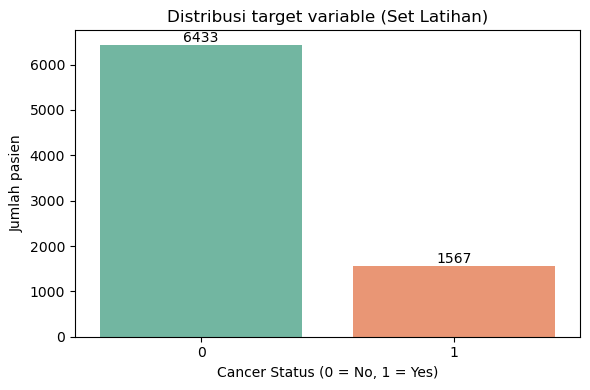

In [13]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=train_data, x='Cancer', palette='Set2')
plt.title('Distribusi target variable (Set Latihan)')
plt.xlabel('Cancer Status (0 = No, 1 = Yes)')
plt.ylabel('Jumlah pasien')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

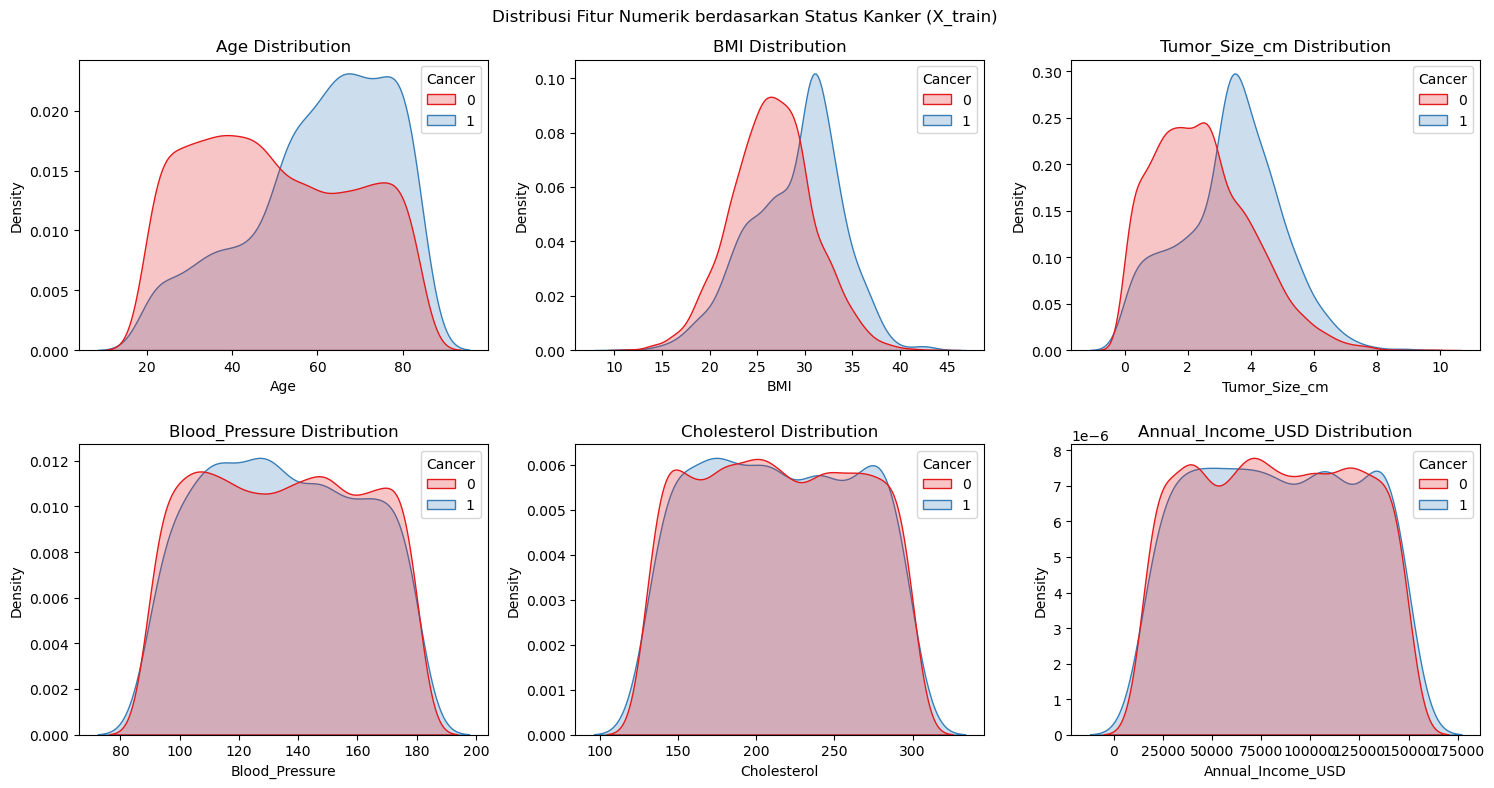

In [14]:
num_cols = ['Age', 'BMI', 'Tumor_Size_cm', 'Blood_Pressure', 'Cholesterol', 'Annual_Income_USD']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Distribusi Fitur Numerik berdasarkan Status Kanker (X_train)')

for i, col in enumerate(num_cols):
    row, c = divmod(i, 3)
    sns.kdeplot(data=train_data, x=col, hue='Cancer', ax=axes[row, c], 
                common_norm=False, fill=True, palette='Set1')
    axes[row, c].set_title(f'{col} Distribution')

plt.tight_layout()
plt.show()

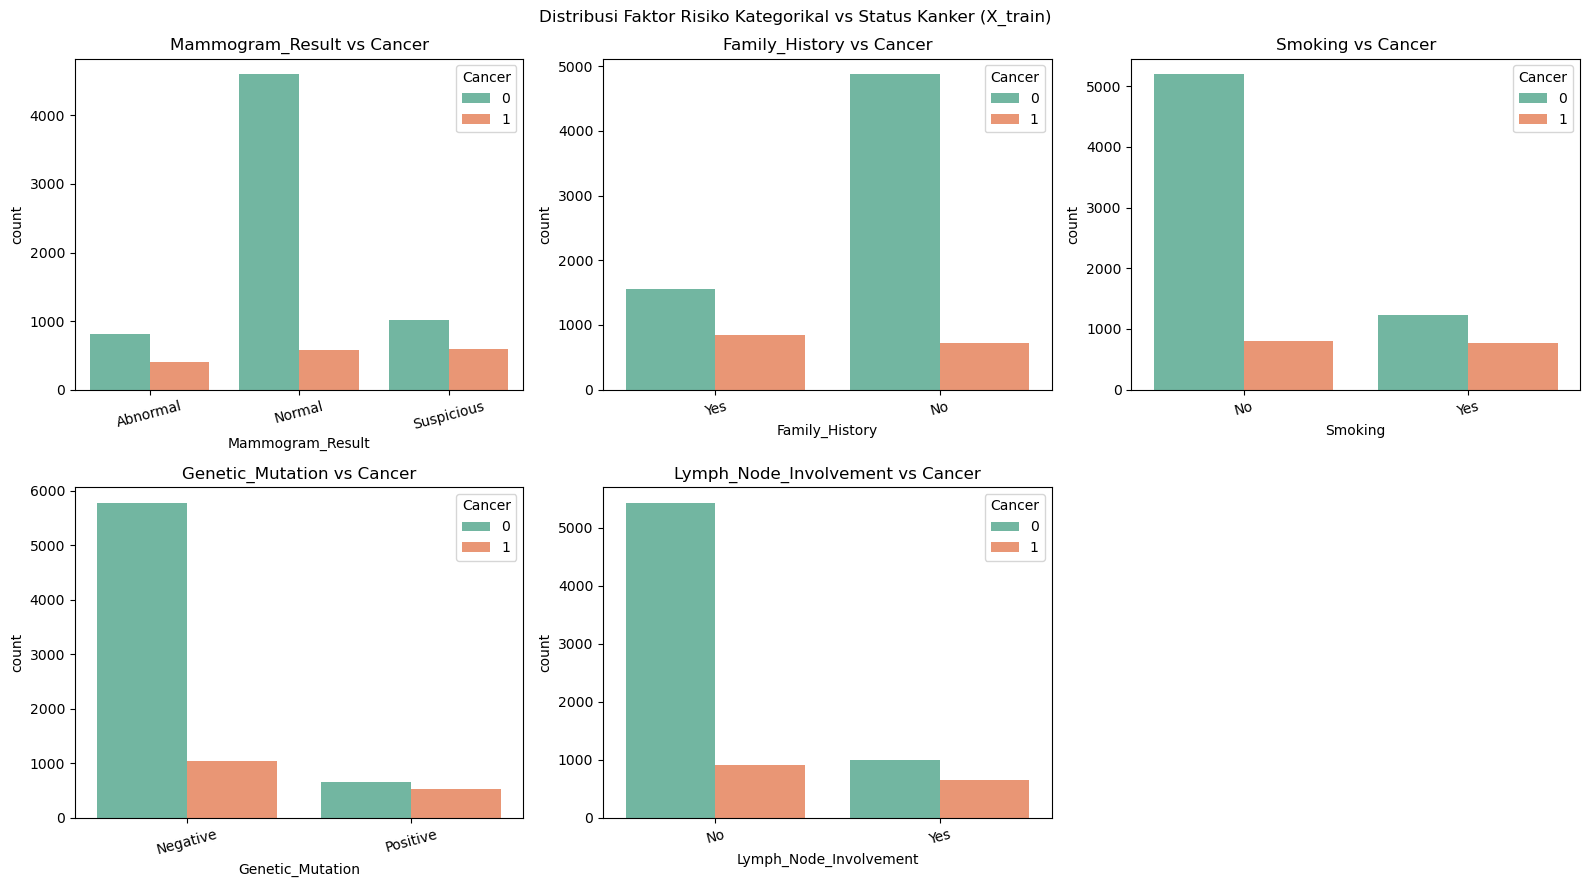

In [15]:
cat_cols = ['Mammogram_Result', 'Family_History', 'Smoking', 'Genetic_Mutation', 'Lymph_Node_Involvement']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Distribusi Faktor Risiko Kategorikal vs Status Kanker (X_train)')

for i, col in enumerate(cat_cols):
    row, c = divmod(i, 3)
    sns.countplot(data=train_data, x=col, hue='Cancer', ax=axes[row, c], palette='Set2')
    axes[row, c].set_title(f'{col} vs Cancer')
    axes[row, c].tick_params(axis='x', rotation=15)

fig.delaxes(axes[1, 2])
plt.tight_layout()
plt.show()

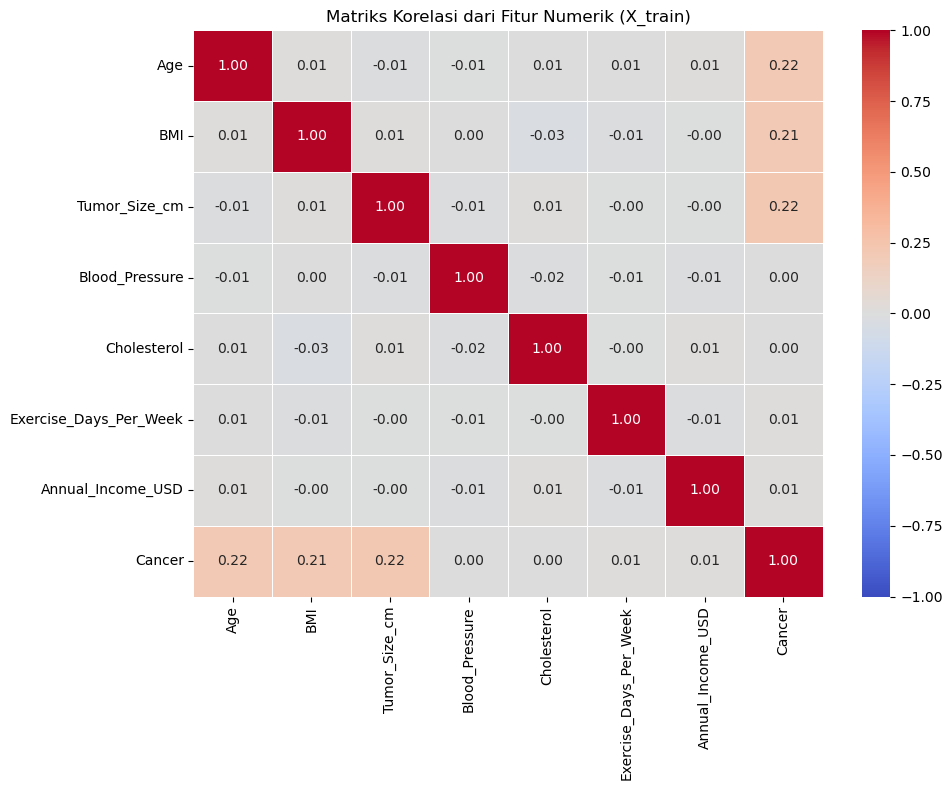

In [16]:
plt.figure(figsize=(10, 8))
numeric_train = train_data.select_dtypes(include=['int64', 'float64'])
corr_matrix = numeric_train.corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriks Korelasi dari Fitur Numerik (X_train)')
plt.tight_layout()
plt.show()

C:\Users\imman\AppData\Local\Temp\ipykernel_9252\3057281003.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='Cancer', y=col, ax=axes[row, c], palette='Set2')
C:\Users\imman\AppData\Local\Temp\ipykernel_9252\3057281003.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='Cancer', y=col, ax=axes[row, c], palette='Set2')
C:\Users\imman\AppData\Local\Temp\ipykernel_9252\3057281003.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='Cancer', y=col, ax=axes[row, c], palette='Set2')
C:\U

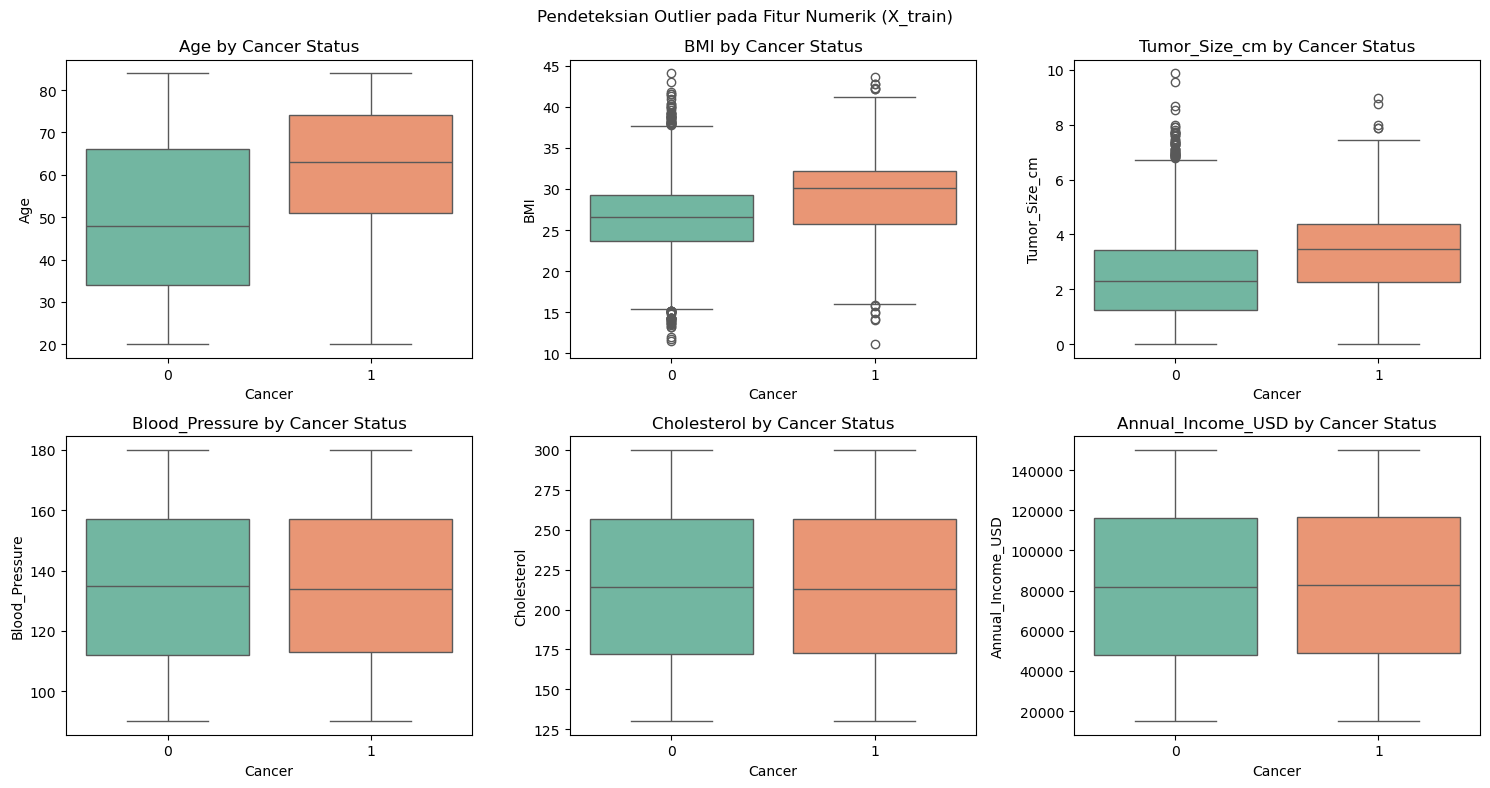

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Pendeteksian Outlier pada Fitur Numerik (X_train)')

for i, col in enumerate(num_cols):
    row, c = divmod(i, 3)
    sns.boxplot(data=train_data, x='Cancer', y=col, ax=axes[row, c], palette='Set2')
    axes[row, c].set_title(f'{col} by Cancer Status')

plt.tight_layout()
plt.show()

In [18]:
numeric_cols = [
    'Age', 'BMI', 'Tumor_Size_cm', 'Blood_Pressure', 
    'Cholesterol', 'Exercise_Days_Per_Week', 'Annual_Income_USD'
]

binary_cols = [
    'Gender', 'Family_History', 'Smoking', 'Alcohol_Consumption', 
    'Hormone_Therapy', 'Menopause_Status', 'Genetic_Mutation', 
    'Lymph_Node_Involvement', 'Diabetes'
]

ordinal_cols = ['Physical_Activity']
ordinal_order = [['Low', 'Moderate', 'High']] 

nominal_cols = ['Mammogram_Result', 'Breastfeeding_History']

In [19]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

binary_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('binary_enc', OrdinalEncoder())
])

ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal_enc', OrdinalEncoder(categories=ordinal_order))
])

nominal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False))
])

In [20]:
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, numeric_cols),
    ('binary', binary_pipeline, binary_cols),
    ('ordinal', ordinal_pipeline, ordinal_cols),
    ('nominal', nominal_pipeline, nominal_cols)
])

In [21]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"X_train processed shape: {X_train_processed.shape}") 
print(f"X_test processed shape:  {X_test_processed.shape}")

X_train processed shape: (8000, 23)
X_test processed shape:  (2000, 23)


In [22]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

results = []

for name, clf in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipe.fit(X_train, y_train)
    
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

comparison_df = pd.DataFrame(results)
print(comparison_df.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Logistic Regression     0.915   0.702479 0.928962  0.800000 0.974062
      Random Forest     0.958   1.000000 0.770492  0.870370 0.976164
  Gradient Boosting     0.981   1.000000 0.896175  0.945245 0.976516


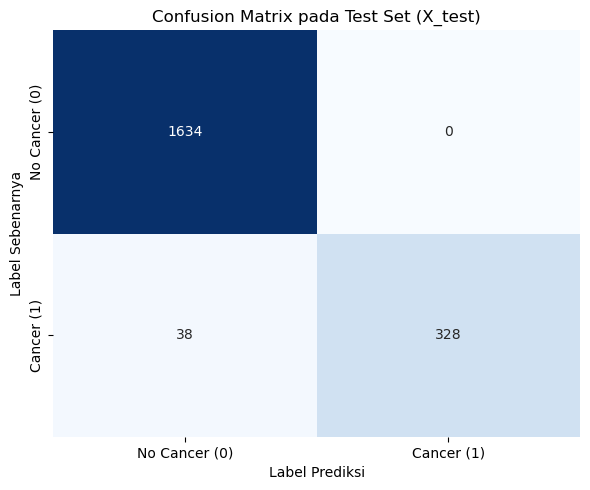

In [23]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Cancer (0)', 'Cancer (1)'],
            yticklabels=['No Cancer (0)', 'Cancer (1)'])
plt.title('Confusion Matrix pada Test Set (X_test)')
plt.xlabel('Label Prediksi')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.show()

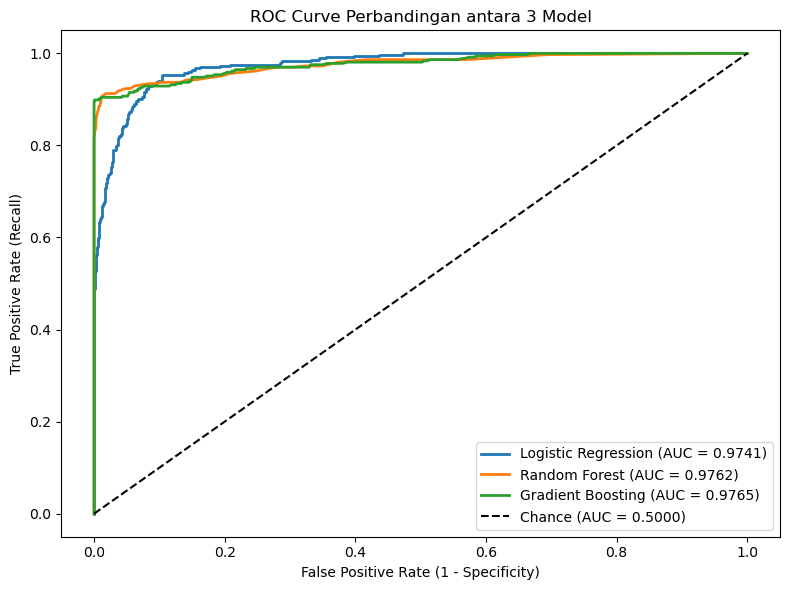

In [24]:
plt.figure(figsize=(8, 6))

for name, clf in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipe.fit(X_train, y_train)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Chance (AUC = 0.5000)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve Perbandingan antara 3 Model')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

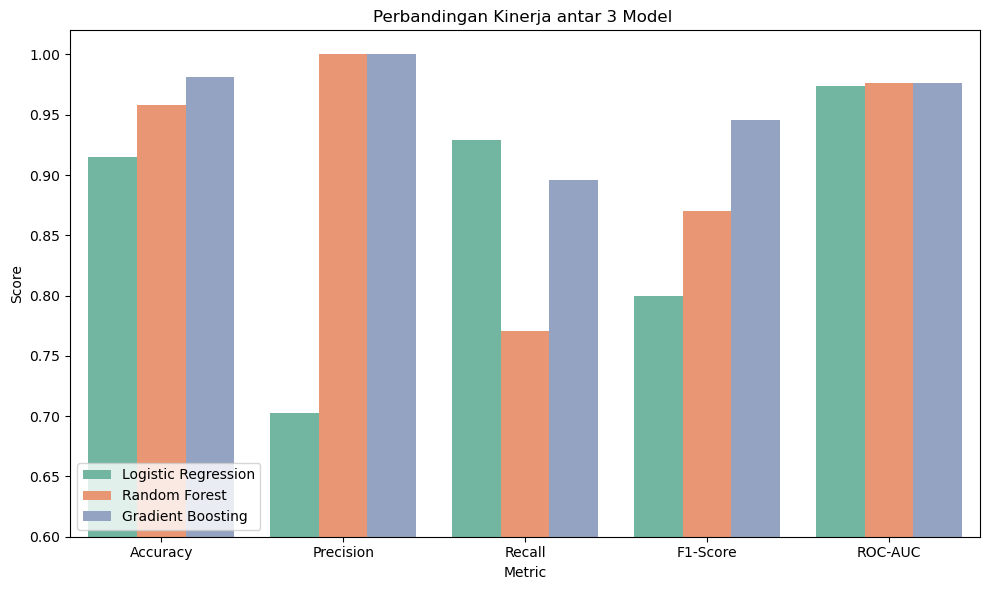

In [25]:
metrics_melted = comparison_df.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(10, 6))
sns.barplot(data=metrics_melted, x='Metric', y='Score', hue='Model', palette='Set2')

plt.ylim(0.60, 1.02)
plt.title('Perbandingan Kinerja antar 3 Model ')
plt.ylabel('Score')
plt.xlabel('Metric')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

In [26]:
best_model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(n_estimators=100, random_state=42))
])

best_model_pipeline.fit(X_train, y_train)

model_filename = 'breast_cancer_GBC_model.pkl'
joblib.dump(best_model_pipeline, model_filename)

print(f"Model berhasil disimpan sebagai '{model_filename}'!\n")

Model berhasil disimpan sebagai 'breast_cancer_GBC_model.pkl'!

